# Uber Fare Prediction

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## 1. Pre-processing

In [2]:
df = pd.read_csv('uber.csv').drop(columns=['Unnamed: 0', 'key'])
raw_rows = len(df)
missing = df.isna().sum()
print(f'Rows loaded: {raw_rows:,}')
print('Missing values:', missing[missing > 0].to_dict() or 'none')
df = df.dropna()
print(f'Rows after dropping missing: {len(df):,}')
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df.pickup_datetime.dt.hour
df['day'] = df.pickup_datetime.dt.day
df['month'] = df.pickup_datetime.dt.month
df['year'] = df.pickup_datetime.dt.year
df['weekday'] = df.pickup_datetime.dt.weekday

# Haversine distance (km) between pickup and drop-off
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
df['distance_km'] = haversine(df.pickup_latitude, df.pickup_longitude, df.dropoff_latitude, df.dropoff_longitude)
df = df.drop(columns=['pickup_datetime'])
print(f'Features: {list(df.columns)}')
df.head().round(3)

Rows loaded: 200,000
Missing values: {'dropoff_longitude': 1, 'dropoff_latitude': 1}
Rows after dropping missing: 199,999
Features: ['fare_amount', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'hour', 'day', 'month', 'year', 'weekday', 'distance_km']


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,weekday,distance_km
0,7.5,-74.000,40.738,-74.000,40.723,1,19,7,5,2015,3,1.683
1,7.7,-73.994,40.728,-73.995,40.750,1,20,17,7,2009,4,2.458
2,12.9,-74.005,40.741,-73.963,40.773,1,21,24,8,2009,0,5.036
3,5.3,-73.976,40.791,-73.965,40.803,3,8,26,6,2009,4,1.662
4,16.0,-73.925,40.744,-73.973,40.761,5,17,28,8,2014,3,4.475


## 2. Outliers

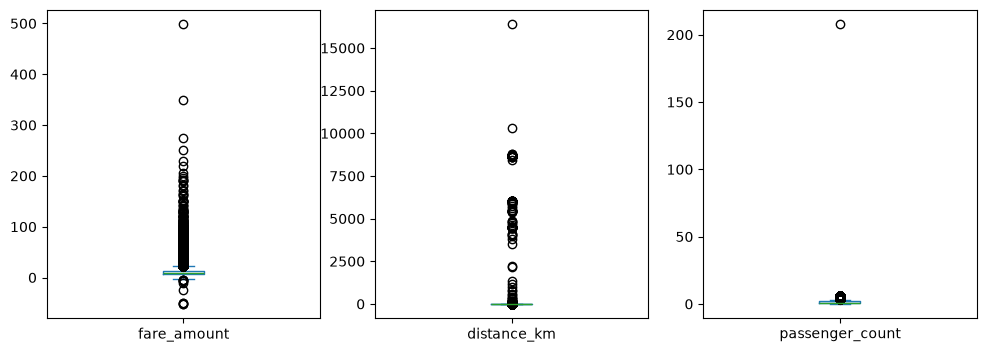

Removed 30980 rows, 169019 remain


In [3]:
cols = ['fare_amount', 'distance_km', 'passenger_count']
df[cols].plot(kind='box', subplots=True, layout=(1, 3), figsize=(12, 4)); plt.show()

# Remove invalid values, then IQR-based outliers on fare and distance
n0 = len(df)
df = df[(df.fare_amount > 0) & (df.passenger_count.between(1, 6)) & (df.distance_km > 0)
        & df.pickup_latitude.between(-90, 90) & df.dropoff_latitude.between(-90, 90)
        & df.pickup_longitude.between(-180, 180) & df.dropoff_longitude.between(-180, 180)]
for c in ['fare_amount', 'distance_km']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    df = df[df[c].between(q1 - 1.5*iqr, q3 + 1.5*iqr)]
print(f'Removed {n0 - len(df)} rows, {len(df)} remain')

## 3. Correlation

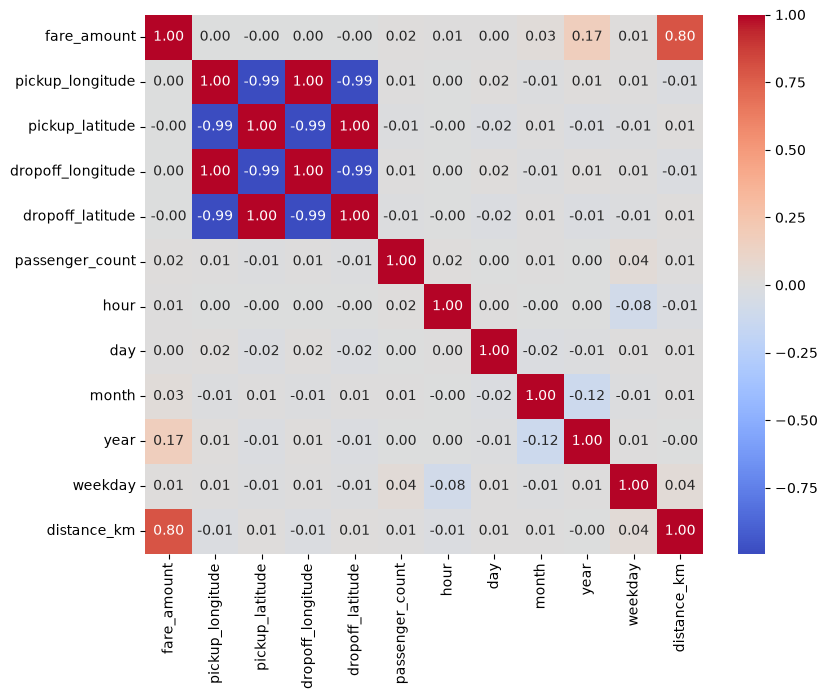

Strongest correlation with fare_amount: distance_km (0.80)
Weakest: pickup_longitude (0.00)
Excluded from Linear Regression (correlation = 0.00): ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'day']


In [4]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm'); plt.show()
corr = df.corr()['fare_amount'].drop('fare_amount')
print(f"Strongest correlation with fare_amount: {corr.abs().idxmax()} ({corr[corr.abs().idxmax()]:.2f})")
print(f"Weakest: {corr.abs().idxmin()} ({corr[corr.abs().idxmin()]:.2f})")

# Features with correlation 0.00 (rounded to 2 decimals): dropped for Linear Regression only
zero_corr = corr[corr.round(2) == 0].index.tolist()
print(f'Excluded from Linear Regression (correlation = 0.00): {zero_corr}')

## 4. Models

### Comparison

In [5]:
X = df.drop(columns='fare_amount'); y = df.fare_amount
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

models = {'Linear Regression': LinearRegression(),
          'Random Forest': RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)}
rows = []
for name, m in models.items():
    cols = X.columns.drop(zero_corr) if name == 'Linear Regression' else X.columns  # Random Forest uses all features
    m.fit(X_tr[cols], y_tr); p = m.predict(X_te[cols])
    rows.append({'Model': name, 'R2': r2_score(y_te, p),
                 'RMSE': np.sqrt(mean_squared_error(y_te, p)), 'MAE': mean_absolute_error(y_te, p)})
pd.DataFrame(rows).set_index('Model').round(4)

,R2,RMSE,MAE
Model,,,
Linear Regression,0.6708,2.1339,1.5250
Random Forest,0.7482,1.8663,1.2985


### (a) Linear Regression

In [6]:
lr = models['Linear Regression']
print('Intercept:', round(lr.intercept_, 4))
pd.Series(lr.coef_, index=X.columns.drop(zero_corr), name='Coefficient').round(4).sort_values()

Intercept: -726.6746


weekday           -0.0326
hour               0.0086
passenger_count    0.0337
month              0.0524
year               0.3629
distance_km        2.0700
Name: Coefficient, dtype: float64

### (b) Random Forest

In [7]:
rf = models['Random Forest']
pd.Series(rf.feature_importances_, index=X.columns, name='Importance').round(4).sort_values(ascending=False)

distance_km          0.6765
year                 0.0517
dropoff_latitude     0.0483
dropoff_longitude    0.0436
pickup_longitude     0.0405
pickup_latitude      0.0363
hour                 0.0335
day                  0.0235
month                0.0211
weekday              0.0174
passenger_count      0.0078
Name: Importance, dtype: float64

**Conclusion:** the model with the higher R² and lower RMSE/MAE is the better predictor. Random Forest typically wins because it captures non-linear effects (e.g. time of day, year-based fare changes) that Linear Regression cannot.